# **Lab 8 - Edge Detection**

**Name:** Mohammad Buhamad
**University ID:** 2240005142

## Setup

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Bird.png'

## Task 1: Apply Edge Detection Methods



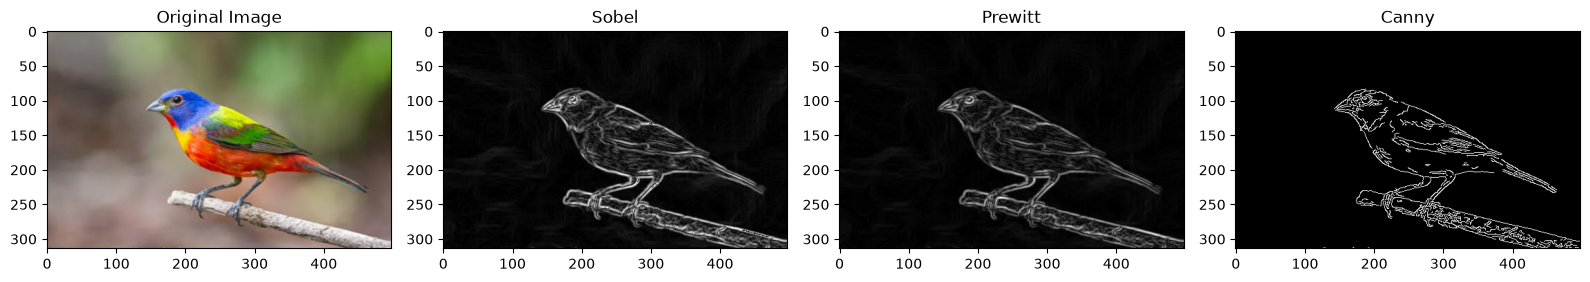

In [2]:
# 1. Load the image
img = cv2.imread(imgFile)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# 2. Sobel Edge Detector
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = cv2.magnitude(sobelx, sobely)
sobel_final = np.uint8(np.absolute(sobel_combined))

# 3. Prewitt Edge Detector
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)
prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_final = np.uint8(np.absolute(prewitt_combined))

# 4. Canny Edge Detector
canny_edges = cv2.Canny(gray, 100, 200)

# 5. Display original image and the three edge maps
plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Image')
plt.subplot(1, 4, 2), plt.imshow(sobel_final, cmap='gray'), plt.title('Sobel')
plt.subplot(1, 4, 3), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt')
plt.subplot(1, 4, 4), plt.imshow(canny_edges, cmap='gray'), plt.title('Canny')
plt.tight_layout()
plt.show()

## Task 2: Investigate the Effect of Canny Thresholds



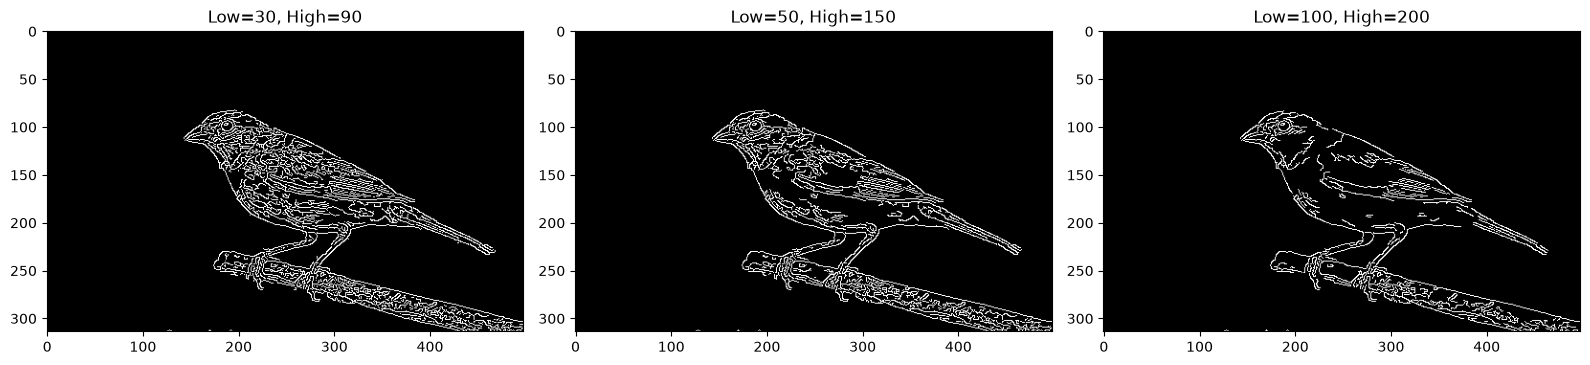

In [3]:
# Three threshold pairs to compare
threshold_pairs = [(30, 90), (50, 150), (100, 200)]

plt.figure(figsize=(16, 5))
for i, (low, high) in enumerate(threshold_pairs, start=1):
    edges = cv2.Canny(gray, low, high)
    plt.subplot(1, 3, i)
    plt.imshow(edges, cmap='gray')
    plt.title(f'Low={low}, High={high}')
plt.tight_layout()
plt.show()